In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import statsmodels.api as sm
print("Succesfully Import Libraries")

Succesfully Import Libraries


In [19]:
df = pd.read_excel("spread_locator_dataset.xlsx")

amount = df["transaction_amount"]          # the money column (continuous)
count = df["transaction_count"]            # weekly count per customer (discrete)

print(df.head())
print("\nRows, columns:", df.shape)
print("Missing values:", df.isna().sum().sum())
print("\nAmount summary:\n", amount.describe().round(2))
print("\nSkewness of amount:", round(stats.skew(amount), 2), "(0 = symmetric, >1 = strongly right-skewed)")

                         transaction_id customer_id  transaction_amount  \
0  e98aa092-3770-4fdb-9502-5b5a6a244811    CUST2824             3821.34   
1  11ba6918-dba0-41e5-96cf-f5a7b95f0103    CUST1409             2781.84   
2  82b7654b-6eb7-4579-89a0-1a9edec0a7bb    CUST5506             4120.97   
3  f7166574-f400-4d53-b526-0b11f6619ddf    CUST5012             6383.78   
4  8632fe26-b507-4068-9c68-1b2fa04fecb3    CUST4657             2651.61   

  transaction_date  transaction_count region transaction_status  
0       2023-01-26                  3  North               Fail  
1       2023-01-28                  0   East               Fail  
2       2023-01-28                  0  South               Fail  
3       2023-01-18                  2  South            Success  
4       2023-01-04                  4  North            Success  

Rows, columns: (220, 7)
Missing values: 0

Amount summary:
 count      220.00
mean      3365.19
std       1985.71
min        804.42
25%       2124.20
50

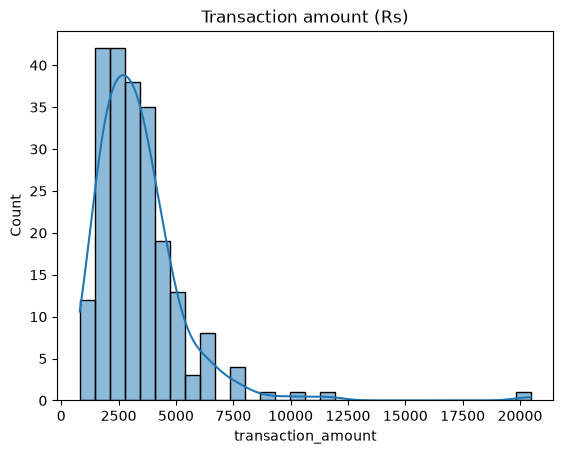

In [20]:
sns.histplot(amount, bins=30, kde=True)
plt.title("Transaction amount (Rs)")
plt.show()



===== TASK 1: Bernoulli & Binomial =====
Bernoulli: P(Success) = 0.445  P(Fail) = 0.555
Bernoulli: P(at least 1 transaction in the week) = 0.932

Binomial fit: n = 9, p = 0.317


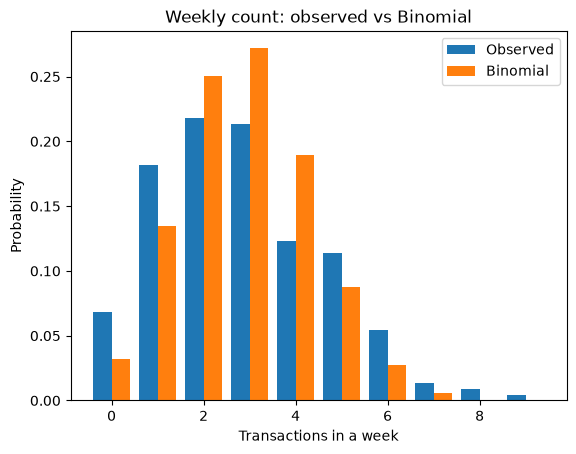

Real data      -> mean: 2.85  variance: 3.23
Binomial model -> mean: 2.85  variance: 1.95
Real variance is bigger than the Binomial's, so the Binomial fits poorly.


In [21]:
print("\n===== TASK 1: Bernoulli & Binomial =====")

# Bernoulli = one yes/no outcome. Success = 1, Fail = 0.
success = (df["transaction_status"] == "Success").astype(int)
p_success = success.mean()                 # best estimate of p is just the average of 0/1 values
print("Bernoulli: P(Success) =", round(p_success, 3), " P(Fail) =", round(1 - p_success, 3))

# Occurrence = did the customer make at least one transaction that week?
occurred = (count >= 1).astype(int)
print("Bernoulli: P(at least 1 transaction in the week) =", round(occurred.mean(), 3))

# Binomial = number of successes in n tries. n is not given, so we assume
# n = the largest weekly count seen in the data. Then p = mean / n.
n = int(count.max())
p = count.mean() / n
print(f"\nBinomial fit: n = {n}, p = {p:.3f}")

# Compare real counts with what a Binomial would predict
values = np.arange(0, n + 1)
observed = count.value_counts(normalize=True).reindex(values, fill_value=0)
expected = stats.binom.pmf(values, n, p)

plt.bar(values - 0.2, observed, width=0.4, label="Observed")
plt.bar(values + 0.2, expected, width=0.4, label="Binomial")
plt.xlabel("Transactions in a week"); plt.ylabel("Probability")
plt.title("Weekly count: observed vs Binomial"); plt.legend()
plt.show()

# A Binomial must have variance SMALLER than its mean. Check:
print("Real data      -> mean:", round(count.mean(), 2), " variance:", round(count.var(), 2))
print("Binomial model -> mean:", round(n * p, 2), " variance:", round(n * p * (1 - p), 2))
print("Real variance is bigger than the Binomial's, so the Binomial fits poorly.")


===== TASK 2: Poisson =====
Average transactions per day (lambda): 7.1
Variance: 5.29 (Poisson expects variance ~ mean)


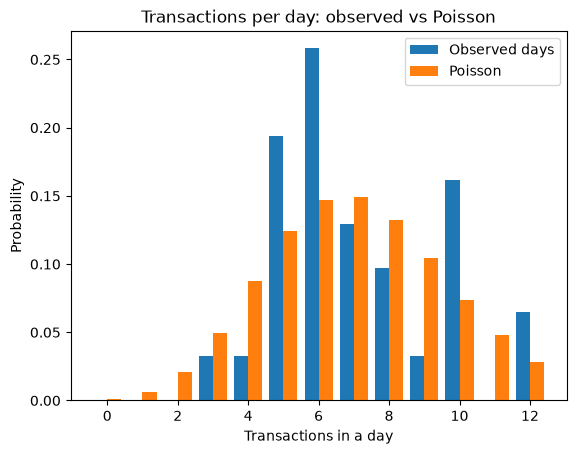

P(10 or more transactions in a day) = 0.179


In [22]:
print("\n===== TASK 2: Poisson =====")

# Count how many transactions happened on each day
all_days = pd.date_range("2023-01-01", "2023-01-31")
per_day = df.groupby("transaction_date").size().reindex(all_days, fill_value=0)

lam = per_day.mean()                       # Poisson has one parameter: lambda = average rate
print("Average transactions per day (lambda):", round(lam, 2))
print("Variance:", round(per_day.var(), 2), "(Poisson expects variance ~ mean)")

values = np.arange(0, per_day.max() + 1)
observed = per_day.value_counts(normalize=True).reindex(values, fill_value=0)
expected = stats.poisson.pmf(values, lam)

plt.bar(values - 0.2, observed, width=0.4, label="Observed days")
plt.bar(values + 0.2, expected, width=0.4, label="Poisson")
plt.xlabel("Transactions in a day"); plt.ylabel("Probability")
plt.title("Transactions per day: observed vs Poisson"); plt.legend()
plt.show()

print("P(10 or more transactions in a day) =", round(stats.poisson.sf(9, lam), 3))


===== TASK 3: Log-Normal vs Power Law =====
Normal     KS distance = 0.140   p-value = 0.0003
Log-Normal KS distance = 0.038   p-value = 0.8999
Power law  KS distance = 0.322   p-value = 0.0000
Smaller KS distance + larger p-value = better fit.


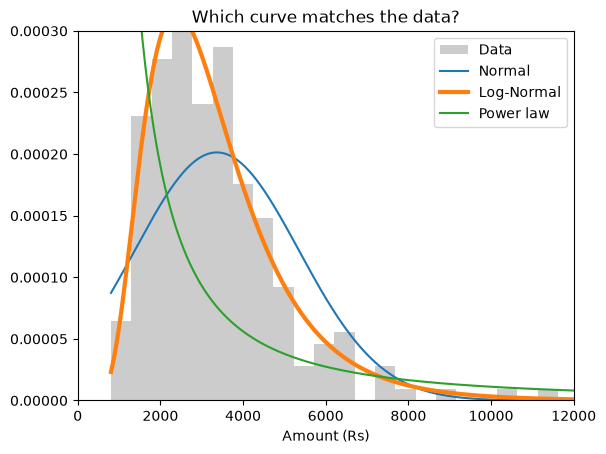

In [23]:
print("\n===== TASK 3: Log-Normal vs Power Law =====")

# Fit three models. floc=0 means "values start at 0".
mean_n, sd_n = stats.norm.fit(amount)                      # Normal (for comparison)
shape, loc, scale = stats.lognorm.fit(amount, floc=0)      # Log-Normal
b, loc_p, scale_p = stats.pareto.fit(amount, floc=0)       # Power law (Pareto)

# KS test: small p-value (< 0.05) = the model does NOT fit the data
for name, dist, args in [("Normal", stats.norm, (mean_n, sd_n)),
                         ("Log-Normal", stats.lognorm, (shape, 0, scale)),
                         ("Power law", stats.pareto, (b, 0, scale_p))]:
    stat, pvalue = stats.kstest(amount, dist.cdf, args=args)
    print(f"{name:10s} KS distance = {stat:.3f}   p-value = {pvalue:.4f}")
print("Smaller KS distance + larger p-value = better fit.")

x = np.linspace(amount.min(), 12000, 500)
plt.hist(amount, bins=40, density=True, alpha=0.4, color="grey", label="Data")
plt.plot(x, stats.norm.pdf(x, mean_n, sd_n), label="Normal")
plt.plot(x, stats.lognorm.pdf(x, shape, 0, scale), lw=3, label="Log-Normal")
plt.plot(x, stats.pareto.pdf(x, b, 0, scale_p), label="Power law")
plt.xlim(0, 12000); plt.ylim(0, 0.0003)
plt.title("Which curve matches the data?"); plt.xlabel("Amount (Rs)"); plt.legend()
plt.show()


===== TASK 4: Q-Q Plot =====


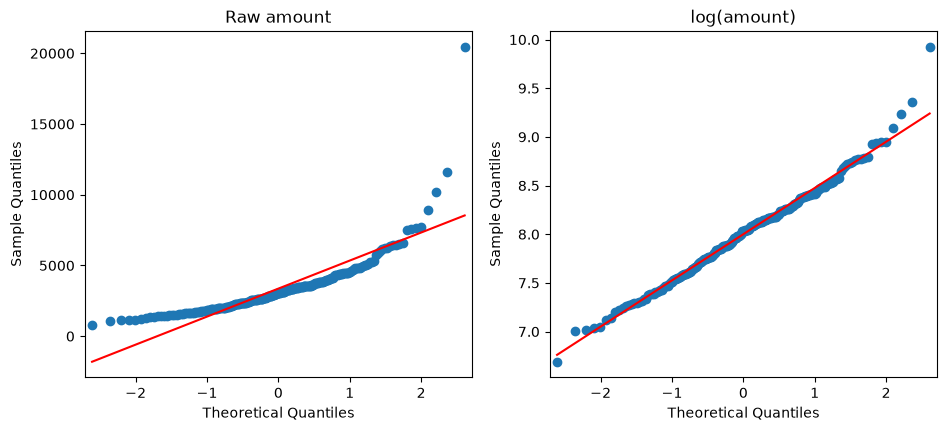

Shapiro p-value, raw amount : 1.9104196066327e-18
Shapiro p-value, log(amount): 0.106


In [24]:
print("\n===== TASK 4: Q-Q Plot =====")

# Points on the red line = normal. Curving away = not normal.
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
sm.qqplot(amount, line="s", ax=axes[0]);          axes[0].set_title("Raw amount")
sm.qqplot(np.log(amount), line="s", ax=axes[1]);  axes[1].set_title("log(amount)")
plt.show()

# Shapiro-Wilk test: p < 0.05 means "not normal"
print("Shapiro p-value, raw amount :", stats.shapiro(amount).pvalue)
print("Shapiro p-value, log(amount):", round(stats.shapiro(np.log(amount)).pvalue, 3))



===== TASK 5: Box-Cox =====
Best lambda: -0.181 (close to 0 means it behaves like a log transform)
Skewness before: 3.73  after: -0.01
Shapiro p-value after Box-Cox: 0.642


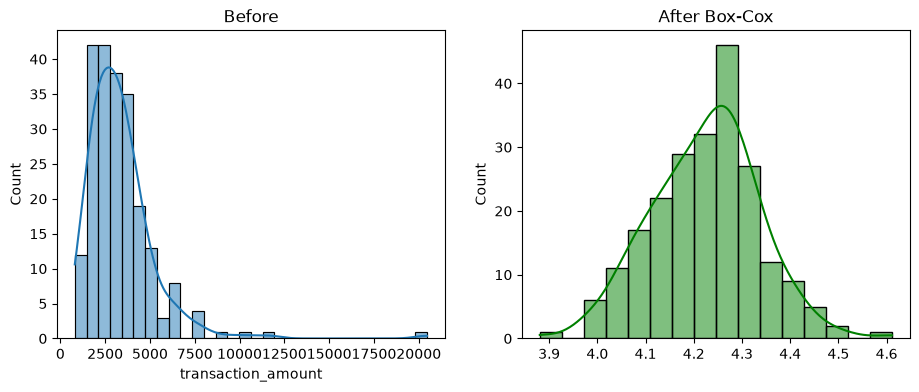

In [25]:
print("\n===== TASK 5: Box-Cox =====")

# Box-Cox finds the power (lambda) that makes the data most normal-looking
amount_bc, lam_bc = stats.boxcox(amount)
print("Best lambda:", round(lam_bc, 3), "(close to 0 means it behaves like a log transform)")
print("Skewness before:", round(stats.skew(amount), 2), " after:", round(stats.skew(amount_bc), 2))
print("Shapiro p-value after Box-Cox:", round(stats.shapiro(amount_bc).pvalue, 3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.histplot(amount, kde=True, ax=axes[0]);     axes[0].set_title("Before")
sns.histplot(amount_bc, kde=True, ax=axes[1], color="green"); axes[1].set_title("After Box-Cox")
plt.show()

In [26]:
print("\n===== TASK 6: Z-scores =====")

mean, std = amount.mean(), amount.std()
df["z_score"] = (amount - mean) / std      # z = how many std-devs away from the mean

z_5000 = (5000 - mean) / std
p_normal = 1 - stats.norm.cdf(z_5000)      # chance of being ABOVE 5000 if data were Normal
print("Mean:", round(mean, 2), " Std:", round(std, 2))
print("z-score of 5000:", round(z_5000, 2))
print("P(amount > 5000), Normal / z-score method:", round(p_normal, 3))

# Better estimate: do the same z-score maths on log(amount)
z_log = (np.log(5000) - np.log(amount).mean()) / np.log(amount).std()
print("P(amount > 5000), Log-Normal method      :", round(1 - stats.norm.cdf(z_log), 3))

# What really happened in the data
print("P(amount > 5000), actual data            :", round((amount > 5000).mean(), 3))

outliers = df[df["z_score"].abs() > 3]
print("\nOutliers (|z| > 3):")
print(outliers[["transaction_amount", "z_score", "region"]].round(2))


===== TASK 6: Z-scores =====
Mean: 3365.19  Std: 1985.71
z-score of 5000: 0.82
P(amount > 5000), Normal / z-score method: 0.205
P(amount > 5000), Log-Normal method      : 0.139
P(amount > 5000), actual data            : 0.114

Outliers (|z| > 3):
     transaction_amount  z_score region
113            10215.09     3.45  North
179            11615.37     4.15  South
209            20462.84     8.61  North



===== TASK 7: PDF and CDF =====


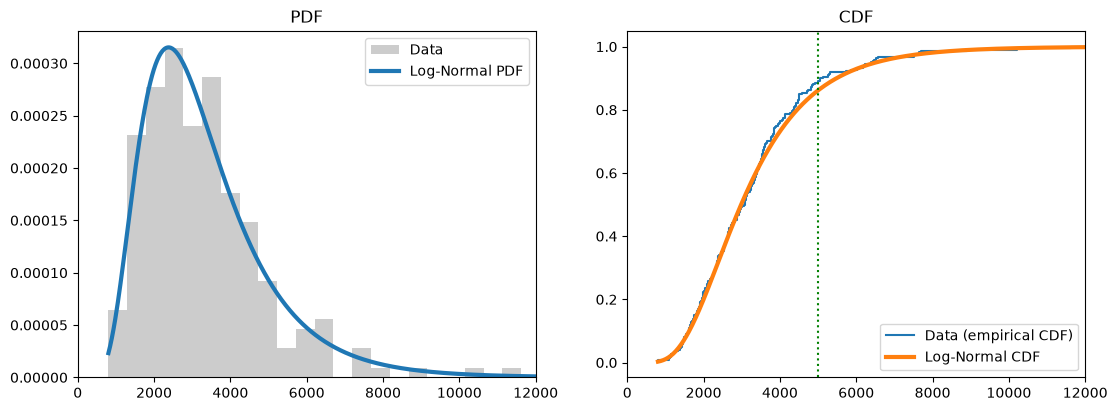

In [27]:
print("\n===== TASK 7: PDF and CDF =====")

x = np.linspace(amount.min(), 12000, 500)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# PDF = how dense the data is at each amount (the "shape")
axes[0].hist(amount, bins=40, density=True, alpha=0.4, color="grey", label="Data")
axes[0].plot(x, stats.lognorm.pdf(x, shape, 0, scale), lw=3, label="Log-Normal PDF")
axes[0].set_xlim(0, 12000); axes[0].set_title("PDF"); axes[0].legend()

# CDF = chance that amount is <= x (always climbs from 0 to 1)
sorted_amt = np.sort(amount)
ecdf = np.arange(1, len(amount) + 1) / len(amount)
axes[1].step(sorted_amt, ecdf, label="Data (empirical CDF)")
axes[1].plot(x, stats.lognorm.cdf(x, shape, 0, scale), lw=3, label="Log-Normal CDF")
axes[1].axvline(5000, color="green", ls=":")
axes[1].set_xlim(0, 12000); axes[1].set_title("CDF"); axes[1].legend()
plt.show()


In [28]:
print("\n===== TASK 8: Conclusion =====")
print("""
Best distribution for transaction_amount: LOG-NORMAL
  - KS test: Log-Normal is not rejected; Normal and Power law are rejected.
  - Q-Q plot: raw amounts curve away from the line, log(amount) follows it.
  - Box-Cox lambda is near 0, i.e. a log transform makes the data normal.
  - P(amount > 5000): Log-Normal ~14% is close to the real ~11%; Normal says ~20% (too high).

Other variables:
  - Transaction status  -> Bernoulli (about 44.5% success)
  - Transactions per day -> roughly Poisson (about 7 per day)
  - Weekly count per customer -> Binomial fits poorly (variance too large)

Decision-making tips:
  - Use the median (about Rs 3,000), not the mean, as the typical amount.
  - Set alert limits using Log-Normal quantiles, not mean +/- 3 std.
  - Review the 3 very large transactions (|z| > 3) manually.
  - About 55% of transactions fail - investigate why.
""")


===== TASK 8: Conclusion =====

Best distribution for transaction_amount: LOG-NORMAL
  - KS test: Log-Normal is not rejected; Normal and Power law are rejected.
  - Q-Q plot: raw amounts curve away from the line, log(amount) follows it.
  - Box-Cox lambda is near 0, i.e. a log transform makes the data normal.
  - P(amount > 5000): Log-Normal ~14% is close to the real ~11%; Normal says ~20% (too high).

Other variables:
  - Transaction status  -> Bernoulli (about 44.5% success)
  - Transactions per day -> roughly Poisson (about 7 per day)
  - Weekly count per customer -> Binomial fits poorly (variance too large)

Decision-making tips:
  - Use the median (about Rs 3,000), not the mean, as the typical amount.
  - Set alert limits using Log-Normal quantiles, not mean +/- 3 std.
  - Review the 3 very large transactions (|z| > 3) manually.
  - About 55% of transactions fail - investigate why.

